# 把net的Conv-4换成Bottleneck

In [1]:
import torch
import torch.nn as nn
import yaml
import torch.optim as optim
import os
import matplotlib.pyplot as plt
from data_processor_3 import process_image

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC']
plt.rcParams['axes.unicode_minus'] = False

## 定义一个残差块

In [2]:
class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, in_channels, mid_channels, stride=1):
        super().__init__()
        out_channels = mid_channels * self.expansion

        self.conv1 = nn.Conv2d(in_channels, mid_channels, 1, bias=False)
        self.bn1   = nn.BatchNorm2d(mid_channels)

        self.conv2 = nn.Conv2d(mid_channels, mid_channels, 3,
                               stride=stride, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(mid_channels)

        self.conv3 = nn.Conv2d(mid_channels, out_channels, 1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        # 若输入输出维度不匹配，用 1x1 卷积投影
        if in_channels != out_channels or stride != 1:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.downsample = None

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        out = out + identity
        return self.relu(out)

## 改一下net

In [3]:
class Model_with_Bottleneck(nn.Module):
    def __init__(self):
        super(Model_with_Bottleneck, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(96, 256, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(256, 384, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(384),
            nn.ReLU(inplace=True),

             # 替换 Conv4
            Bottleneck(384, 96),

            nn.Conv2d(384, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(9216, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(4096, 2),
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

## 把train拿过来用

In [5]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * y.size(0)
            correct    += (out.argmax(dim=1) == y).sum().item()
            total      += y.size(0)

    return total_loss / total, correct / total

def draw_result(loss_train, loss_val, acc_train, acc_val):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(loss_train, label='train loss', color='blue')
    axes[0].plot(loss_val,   label='val loss',   color='orange')
    axes[0].set_xlabel('epoch')
    axes[0].set_title('Loss')
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(acc_train, label='train acc', color='blue')
    axes[1].plot(acc_val,   label='val acc',   color='orange')
    axes[1].set_xlabel('epoch')
    axes[1].set_title('Accuracy')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()

    # 自动避免覆盖
    base, ext = 'Bottleneck替换', '.jpg'
    filename = f"{base}{ext}"
    counter = 2
    while os.path.exists(filename):
        filename = f"{base}{counter}{ext}"
        counter += 1
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"图片已保存为 {filename}")
    plt.show()

    
#-----------------超参数配置-------------------------
epochs = 20
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = Model_with_Bottleneck().to(device)
lr = 1e-4
optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

with open("config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.load(f, Loader=yaml.FullLoader)
root = cfg["dataset_root"]
train_loader, val_loader = process_image(root)

[split] train: 20000, val: 5000, val_ratio=0.2, seed=42


epoch 01 | train loss=0.5963 acc=0.6893 | val loss=0.5926 acc=0.6870
epoch 02 | train loss=0.4013 acc=0.8212 | val loss=0.3952 acc=0.8150
epoch 03 | train loss=0.3044 acc=0.8690 | val loss=0.2975 acc=0.8712
epoch 04 | train loss=0.2571 acc=0.8901 | val loss=0.3542 acc=0.8420
epoch 05 | train loss=0.2290 acc=0.9051 | val loss=0.2498 acc=0.8936
epoch 06 | train loss=0.2088 acc=0.9154 | val loss=0.2892 acc=0.8780
epoch 07 | train loss=0.1886 acc=0.9222 | val loss=0.2654 acc=0.8880
epoch 08 | train loss=0.1749 acc=0.9295 | val loss=0.2713 acc=0.8778
epoch 09 | train loss=0.1622 acc=0.9344 | val loss=0.2266 acc=0.9030
epoch 10 | train loss=0.1529 acc=0.9373 | val loss=0.1770 acc=0.9236
epoch 11 | train loss=0.1415 acc=0.9430 | val loss=0.1954 acc=0.9146
epoch 12 | train loss=0.1280 acc=0.9485 | val loss=0.2157 acc=0.9094
epoch 13 | train loss=0.1258 acc=0.9497 | val loss=0.1587 acc=0.9306
epoch 14 | train loss=0.1199 acc=0.9518 | val loss=0.2912 acc=0.8780
epoch 15 | train loss=0.1158 acc=0

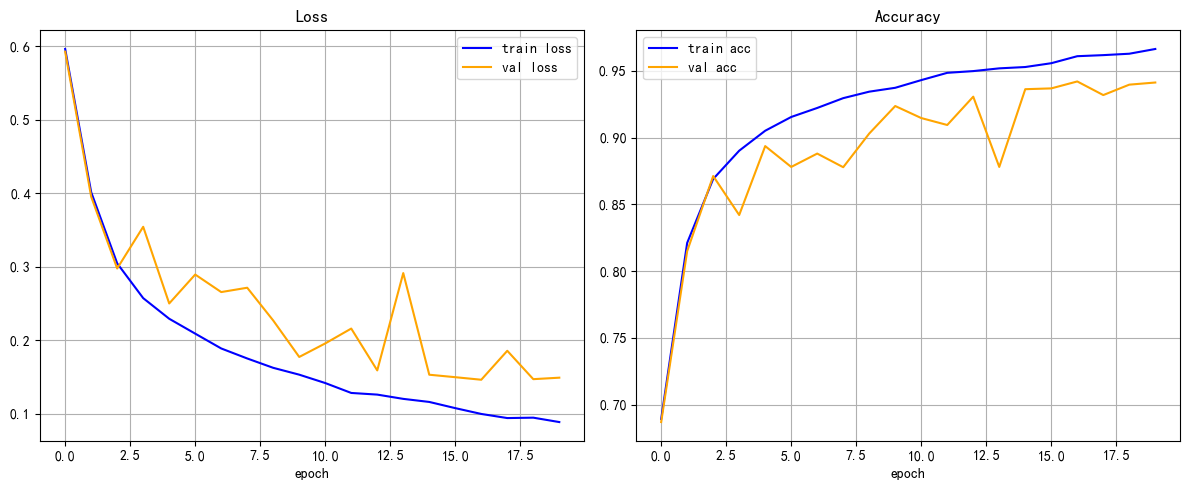

In [6]:
loss_train, acc_train = [], []
loss_val,   acc_val   = [], []

for epoch in range(1, epochs+1):
    tr_loss, tr_acc = run_epoch(model, train_loader, loss_fn, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader,   loss_fn)

    loss_train.append(tr_loss); acc_train.append(tr_acc)
    loss_val.append(va_loss);   acc_val.append(va_acc)

    print(f"epoch {epoch:02d} | "
          f"train loss={tr_loss:.4f} acc={tr_acc:.4f} | "
          f"val loss={va_loss:.4f} acc={va_acc:.4f}")
draw_result(loss_train, loss_val, acc_train, acc_val)